### Importando Bibliotecas

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import os
from scipy.fft import fft, fftshift, fftfreq

sample_rate = 25_000_000
bytes_per_sample = 4
n_points = 100_000
INT16_MAX = 32768.0

### Carregando Dados

In [ ]:
def signal_analyze(filename):

    # load data
    filesize = os.path.getsize(filename)
    n_int16 = filesize // 2  # num de int16 que existem no arquivo
    total_samples = filesize // bytes_per_sample
    print(f"Arquivo: {filename}, bytes={filesize:,}, amostras={total_samples:,}")
    # Cria 100.000 números uniformemente espaçados entre 0 e total_samples - 1 
    sample_indices = np.linspace(0, total_samples - 1, num=n_points, dtype=np.int64)
    
    # Cria um acesso direto ao arquivo binário
    mm = np.memmap(filename, dtype=np.int16, mode="r", shape=(n_int16,))
    
    idx_I = 2 * sample_indices
    idx_Q = idx_I + 1

    # podemos normalizar o sinal
    I = mm[idx_I].astype(np.float32) 
    Q = mm[idx_Q].astype(np.float32) 

    iq = I + 1j * Q
    time_axis = sample_indices / sample_rate # pega o segundo de cada amostra

    # Signal Power
    power_db = 10 * np.log10(I**2 + Q**2 + 1e-12)
    print(power_db)

    # Usa uma janela deslizante simples (média móvel)
    window_size = 500       # ajustável — quanto maior, mais suave
    kernel = np.ones(window_size) / window_size
    smooth_power_db = np.convolve(power_db, kernel, mode='same')

    plt.figure(figsize=(12,5))
    plt.plot(time_axis, power_db, '.', color='lightgray', markersize=2, label='Potência instantânea')
    plt.plot(time_axis, smooth_power_db, color='blue', linewidth=1.5, label=f'Potência suavizada (janela={window_size})')
    plt.axvline(120, color='r', linestyle='--', label='Início esperado do spoofing (~120s)')
    plt.title(f"Potência instantânea e suavizada — {n_points} amostras espaçadas")
    plt.xlabel("Tempo (s)")
    plt.ylabel("Potência (dB)")
    plt.grid(True)
    plt.legend()
    plt.tight_layout()
    
    base = os.path.basename(filename)
    base_no_ext = os.path.splitext(base)[0]
    out_path = f"Imagens/{base_no_ext}_power_plot.png"

    plt.savefig(out_path, dpi=300)
    plt.show()
    plt.close()

    # Doppler 
    print("Doppler aproximados")
    win = 2000
    step = 2000
    times_cn0, cn0, doppler = [], [], []
    for i in range(0, len(iq)-win, step):
        seg = iq[i:i+win] * np.hanning(win)
        S = np.abs(fftshift(fft(seg)))**2
        f = fftshift(fftfreq(win, 1/sample_rate))
        sig = S[np.abs(f) < 1e6].sum()
        noise = S[(np.abs(f) > 2e6) & (np.abs(f) < 10e6)].mean()
        cn0.append(10*np.log10(sig/(noise+1e-15)))
        doppler.append(f[np.argmax(S)])
        times_cn0.append(time_axis[i])

    plt.figure(figsize=(10,3))
    plt.plot(times_cn0, doppler)
    plt.title("Doppler estimado (Hz)")
    plt.xlabel("Tempo (s)"); plt.ylabel("Hz")
    plt.grid(True); plt.tight_layout()
    plt.show()

    print("Calculando proxy de C/N0 baseado na potência...")

    window_size_cn0 = 1000
    kernel_cn0 = np.ones(window_size_cn0) / window_size_cn0
    smooth_power_cn0 = np.convolve(power_db, kernel_cn0, mode='same')
    cn0_proxy = smooth_power_cn0 - np.min(smooth_power_cn0)

    plt.figure(figsize=(10,3))
    plt.plot(time_axis, cn0_proxy, color='purple', linewidth=1.5)
    plt.axvline(120, color='r', linestyle='--', label='Início esperado do spoofing (~120s)')
    plt.title("Proxy simples de C/N₀ (baseado na potência suavizada)")
    plt.xlabel("Tempo (s)")
    plt.ylabel("C/N₀ relativo (dB)")
    plt.grid(True)
    plt.legend()
    plt.tight_layout()

    # Salva o gráfico
    base = os.path.basename(filename)
    base_no_ext = os.path.splitext(base)[0]
    out_path_cn0 = f"Imagens/{base_no_ext}_cn0_proxy.png"
    plt.savefig(out_path_cn0, dpi=300)
    plt.show()
    plt.close()



## Análises

### Clean Signal

### Spoofed Signal

Arquivo: ../ds2.bin, bytes=45,717,913,600, amostras=11,429,478,400
[55.215893 50.805435 53.125095 ... 63.34102  48.140343 67.04022 ]


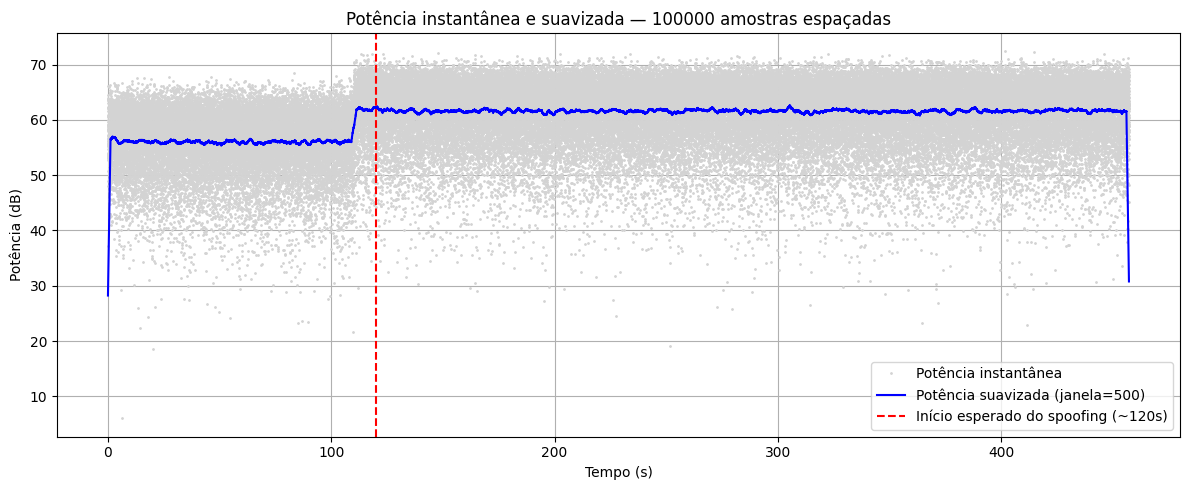

Estimando C/N0 e Doppler aproximados...


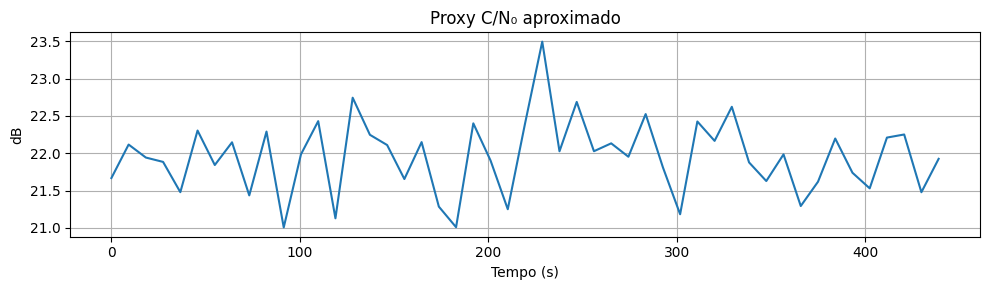

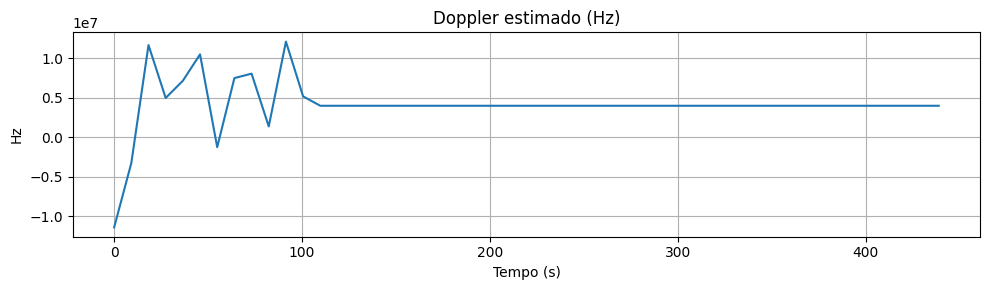

Calculando proxy de C/N0 baseado na potência...


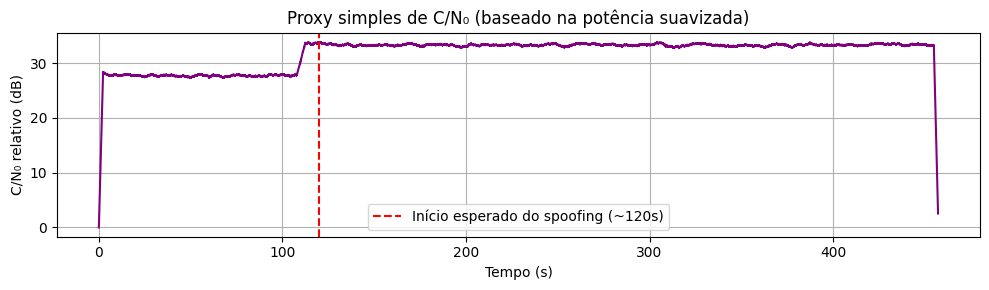

In [10]:
filename = '../ds2.bin'

signal_analyze(filename)